In [1]:
# ============================================================
# CELL 1: Environment setup, package installation, Drive mount
# ============================================================
!pip install -q rdkit==2026.3.4 pubchempy==1.0.4 scikit-learn==1.6.1 scipy==1.16.3

from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib, time, json, requests
import numpy as np
import pandas as pd
from rdkit import Chem

SEED = 42
np.random.seed(SEED)

PROJECT_DIR = '/content/drive/MyDrive/QSPR_Anthelmintic_repo'   # Colab; set to the repo root when running elsewhere
for sub in ['figures', 'results', 'data']:
    os.makedirs(f'{PROJECT_DIR}/{sub}', exist_ok=True)

# --- record the exact environment (quoted in the Methods and saved to the repo) ---
pkgs = ['rdkit', 'pubchempy', 'numpy', 'pandas', 'scipy', 'statsmodels', 'sklearn', 'matplotlib']
lines = [f'python {sys.version.split()[0]}']
for p in pkgs:
    try:
        lines.append(f'{p} {importlib.import_module(p).__version__}')
    except Exception as e:
        lines.append(f'{p} NOT AVAILABLE ({type(e).__name__})')
lines.append(f'random seed {SEED}')
print('\n'.join(lines))
open(f'{PROJECT_DIR}/results/environment.txt', 'w').write('\n'.join(lines) + '\n')
print('Project directory ready at:', PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
python 3.13.16
rdkit 2026.03.4
pubchempy 1.0.4
numpy 2.1.3
pandas 2.2.3
scipy 1.16.3
statsmodels 0.15.0
sklearn 1.6.1
matplotlib 3.10.0
random seed 42
Project directory ready at: /content/drive/MyDrive/QSPR_Anthelmintic_repo


In [2]:
# ============================================================
# CELL 2 (corrected): Fetch PubChem ConnectivitySMILES + Compute 10 TIs
# ============================================================

drugs = {
    'Albendazole':        2082,
    'Mebendazole':        4030,
    'Thiabendazole':      5430,
    'Oxfendazole':        40854,
    'Flubendazole':       35802,
    'Triclabendazole':    50248,
    'Fenbendazole':       3334,
    'Febantel':           9570638,
    'Ivermectin':         6321424,
    'Doramectin':         9832750,
    'Moxidectin':         9832912,
    'Selamectin':         9578507,
    'Pyrantel':           708857,
    'Oxantel':            5281087,
    'Morantel':           5353792,
    'Praziquantel':       4891,
    'Diethylcarbamazine': 3052,
    'Levamisole':         26879,
    'Niclosamide':        4477,
    'Nitazoxanide':       41684,
    'Rafoxanide':         31475,
    'Closantel':          42574,
    'Oxibendazole':       4622,
    'Eprinomectin':       6444397,
    'Tribendimidine':     3086564,
}

import requests, time
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

session = requests.Session()
retry_strategy = Retry(total=5, backoff_factor=2,
                        status_forcelist=[429, 500, 502, 503, 504],
                        allowed_methods=["GET"])
session.mount("https://", HTTPAdapter(max_retries=retry_strategy))

PUBCHEM_BASE = "https://pubchem.ncbi.nlm.nih.gov/rest/pug"   # <-- fixed hostname

def fetch_connectivity_smiles(cid, max_retries=3):
    url = f"{PUBCHEM_BASE}/compound/cid/{cid}/property/ConnectivitySMILES,MolecularFormula/JSON"
    last_err = None
    for attempt in range(max_retries):
        try:
            r = session.get(url, timeout=20)
            r.raise_for_status()
            props = r.json()['PropertyTable']['Properties'][0]
            return props['ConnectivitySMILES'], props['MolecularFormula']
        except Exception as e:
            last_err = e
            time.sleep(2 * (attempt + 1))
    print(f"  !! FAILED CID {cid}: {last_err}")
    return None, None

def compute_topological_indices(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"RDKit could not parse SMILES: {smiles}")
    mol = Chem.RemoveHs(mol)

    n_atoms = mol.GetNumAtoms()
    degrees = {atom.GetIdx(): atom.GetDegree() for atom in mol.GetAtoms()}
    bonds = mol.GetBonds()

    randic = abc = ga = h_idx = hm = m2 = isi = sdd = azi = 0.0
    m1 = sum(d ** 2 for d in degrees.values())

    for b in bonds:
        du = degrees[b.GetBeginAtomIdx()]
        dv = degrees[b.GetEndAtomIdx()]
        s, p = du + dv, du * dv

        randic += 1 / np.sqrt(p) if p > 0 else 0
        abc    += np.sqrt((s - 2) / p) if p > 0 else 0
        ga     += (2 * np.sqrt(p)) / s if s > 0 else 0
        h_idx  += 2 / s if s > 0 else 0
        hm     += s ** 2
        m2     += p
        isi    += p / s if s > 0 else 0
        sdd    += (du / dv + dv / du) if (du > 0 and dv > 0) else 0
        azi    += (p / (s - 2)) ** 3 if s != 2 else 0

    return {
        'HeavyAtoms': n_atoms, 'NumBonds': mol.GetNumBonds(),
        'Randic': randic, 'ABC': abc, 'GA': ga, 'H': h_idx, 'HM': hm,
        'M1': m1, 'M2': m2, 'ISI': isi, 'SDD': sdd, 'AZI': azi
    }

from rdkit.Chem.rdMolDescriptors import CalcMolFormula
import datetime

CSV = f'{PROJECT_DIR}/data/topological_indices_25drugs.csv'

if os.path.exists(CSV):                       # use the saved file; the results then do not depend on live PubChem
    ti_df = pd.read_csv(CSV)
    print('Loaded saved structures from', CSV, '| retrieved on', ti_df['Retrieved'].iloc[0])
else:
    records, failed = [], []
    for name, cid in drugs.items():
        smiles, formula = fetch_connectivity_smiles(cid)
        if smiles is None:
            failed.append((name, cid))
            continue
        ti = compute_topological_indices(smiles)
        records.append({'Drug': name, 'CID': cid, 'SMILES': smiles,
                        'MolecularFormula': formula, **ti})
        print(f"{name:20s} CID={cid:<9d} {formula:<20s} HeavyAtoms={ti['HeavyAtoms']:<4d}")
        time.sleep(0.3)
    assert not failed, f'PubChem fetch failed for: {failed}'
    ti_df = pd.DataFrame(records)
    ti_df['Retrieved'] = datetime.date.today().isoformat()
    ti_df.to_csv(CSV, index=False)

# --- structure checks (always run) ---
mols = [Chem.MolFromSmiles(s) for s in ti_df['SMILES']]
assert len(ti_df) == 25, f'expected 25 compounds, found {len(ti_df)}'
assert all(m is not None for m in mols), 'a SMILES could not be parsed'
assert all(len(Chem.GetMolFrags(m)) == 1 for m in mols), 'a SMILES has more than one fragment'
assert all(CalcMolFormula(m) == f for m, f in zip(mols, ti_df['MolecularFormula'])), 'formula mismatch'
# M1: vertex form (sum of d^2) must equal the edge form (sum of du + dv)
for m, v in zip(mols, ti_df['M1']):
    assert sum(b.GetBeginAtom().GetDegree() + b.GetEndAtom().GetDegree() for b in m.GetBonds()) == v
print('All structure checks passed:', len(ti_df), 'compounds')
ti_df

Loaded saved structures from /content/drive/MyDrive/QSPR_Anthelmintic_repo/data/topological_indices_25drugs.csv | retrieved on 2026-10-23
All structure checks passed: 25 compounds


,Drug,CID,SMILES,MolecularFormula,HeavyAtoms,NumBonds,Randic,ABC,GA,H,HM,M1,M2,ISI,SDD,AZI,Retrieved
0,Albendazole,2082,CCCSC1=CC2=C(C=C1)N=C(N2)NC(=O)OC,C12H15N3O2S,18,19,8.723877,13.503979,18.509194,8.466667,418.0,88,100.0,20.983333,42.333333,150.765625,2026-10-23
1,Mebendazole,4030,COC(=O)NC1=NC2=C(N1)C=C(C=C2)C(=O)C3=CC=CC=C3,C16H13N3O3,22,24,10.669035,17.068022,23.412207,10.366667,554.0,114,133.0,27.266667,53.333333,192.921875,2026-10-23
2,Thiabendazole,5430,C1=CC=C2C(=C1)NC(=N2)C3=CSC=N3,C10H7N3S,14,16,6.932653,11.232828,15.838367,6.866667,368.0,76,90.0,18.600000,33.333333,134.781250,2026-10-23
3,Oxfendazole,40854,COC(=O)NC1=NC2=C(N1)C=C(C=C2)S(=O)C3=CC=CC=C3,C15H13N3O3S,22,24,10.669035,17.068022,23.412207,10.366667,554.0,114,133.0,27.266667,53.333333,192.921875,2026-10-23
4,Flubendazole,35802,COC(=O)NC1=NC2=C(N1)C=C(C=C2)C(=O)C3=CC=C(C=C3)F,C16H12FN3O3,23,25,11.062882,17.884519,24.237824,10.666667,588.0,120,140.0,28.416667,57.000000,196.296875,2026-10-23
5,Triclabendazole,50248,CSC1=NC2=CC(=C(C=C2N1)Cl)OC3=C(C(=CC=C3)Cl)Cl,C14H9Cl3N2OS,21,23,10.079719,16.429865,22.278232,9.700000,558.0,112,133.0,26.516667,52.666667,183.687500,2026-10-23
6,Fenbendazole,3334,COC(=O)NC1=NC2=C(N1)C=C(C=C2)SC3=CC=CC=C3,C15H13N3O2S,21,23,10.241515,16.332406,22.505773,10.000000,516.0,108,124.0,25.916667,50.333333,182.765625,2026-10-23
7,Febantel,9570638,COCC(=O)NC1=C(C=CC(=C1)SC2=CC=CC=C2)NC(=NC(=O)...,C20H22N4O6S,31,32,14.943422,22.915146,31.042625,14.433333,682.0,146,162.0,34.550000,72.666667,245.515625,2026-10-23
8,Ivermectin,6321424,CCC(C)C1C(CCC2(O1)CC3CC(O2)CC=C(C(C(C=CC=C4COC...,C48H74O14,62,68,29.497426,48.706408,65.402820,28.157143,1754.0,340,413.0,79.476190,160.500000,546.889245,2026-10-23
9,Doramectin,9832750,CC1C=CC=C2COC3C2(C(C=C(C3O)C)C(=O)OC4CC(CC=C(C...,C50H74O14,64,71,30.621217,50.718338,68.573782,29.390476,1818.0,354,430.0,83.259524,164.833333,575.514245,2026-10-23


In [3]:
# ============================================================
# CELL 3: Load ChemSpider (ACD/Labs-predicted) properties and merge with TI data
# ============================================================
import numpy as np
import pandas as pd

PROPS_FILE = f'{PROJECT_DIR}/data/anthelmintic_properties_chemspider.xlsx'   # keep this file in the repo
PROPERTY_SOURCE = 'ChemSpider (ACD/Labs Percepta predicted properties)'
PROPERTY_RETRIEVED = 'YYYY-MM-DD'          # <-- enter the date the values were taken from ChemSpider

assert os.path.exists(PROPS_FILE), f'Copy the Excel file to {PROPS_FILE}'
if PROPERTY_RETRIEVED == 'YYYY-MM-DD':
    print('REMINDER: set PROPERTY_RETRIEVED to the real retrieval date before release.')

props_df = pd.read_excel(PROPS_FILE)
print(f"Raw ChemSpider file shape: {props_df.shape}")
print("Columns found:", list(props_df.columns))

# --- Standardize missing-value markers ---
na_markers = ['N/A', 'NA', 'n/a', 'na', '-', '--', '']
props_df = props_df.replace(na_markers, np.nan)

# --- Normalize column headers to canonical CamelCase ---
column_rename_map = {
    'Boiling Point':             'BoilingPoint',
    'Enthalpy of Vaporization':  'EnthalpyOfVaporization',
    'Flash Point':               'FlashPoint',
    'Molar Refractivity':        'MolarRefractivity',
    'Polarizability':            'Polarizability',
    'Molar Volume':              'MolarVolume',
    'Drug':                      'Drug',
}
props_df = props_df.rename(columns=column_rename_map)

expected_cols = ['Drug', 'BoilingPoint', 'EnthalpyOfVaporization', 'FlashPoint',
                 'MolarRefractivity', 'Polarizability', 'MolarVolume']
missing_cols = [c for c in expected_cols if c not in props_df.columns]
if missing_cols:
    raise ValueError(f"Expected columns not found after renaming: {missing_cols}\n"
                     f"Actual columns: {list(props_df.columns)}")
props_df = props_df[expected_cols]

property_cols = expected_cols[1:]
for col in property_cols:
    props_df[col] = pd.to_numeric(props_df[col], errors='coerce')

# --- Name harmonization (strip whitespace first, then map) ---
name_map = {'Tiabendazole': 'Thiabendazole', 'Ivermectin B1a': 'Ivermectin', 'Eprinomectin B1a': 'Eprinomectin'}
props_df['Drug'] = props_df['Drug'].str.strip().replace(name_map)
ti_df['Drug'] = ti_df['Drug'].str.strip()

# --- Name matching must be exact ---
only_in_ti = set(ti_df['Drug']) - set(props_df['Drug'])
only_in_props = set(props_df['Drug']) - set(ti_df['Drug'])
assert not only_in_ti and not only_in_props, (
    f'Name mismatch. In TI table only: {sorted(only_in_ti)} | in ChemSpider file only: {sorted(only_in_props)}')
print('All', len(ti_df), 'drug names matched exactly.')

# --- Merge ---
merged_df = ti_df.merge(props_df, on='Drug', how='left', validate='one_to_one')
assert merged_df.shape[0] == 25, f'merged_df has {merged_df.shape[0]} rows, expected 25'

# --- Missing-data report (facts only) ---
print("\n--- Missing values per property (n = 25) ---")
missing_sets = {}
for col in property_cols:
    missing_sets[col] = set(merged_df.loc[merged_df[col].isna(), 'Drug'])
    print(f"{col:25s}: {len(missing_sets[col]):2d} missing")
assert len(missing_sets['BoilingPoint']) == len(missing_sets['EnthalpyOfVaporization']) == len(missing_sets['FlashPoint']) == 8
assert missing_sets['BoilingPoint'] == missing_sets['EnthalpyOfVaporization'] == missing_sets['FlashPoint']
assert all(len(missing_sets[c]) == 0 for c in ['MolarRefractivity', 'Polarizability', 'MolarVolume'])
print('Compounds with no BP / enthalpy / flash-point value in the source:', sorted(missing_sets['BoilingPoint']))

# --- Data note: MR and polarizability are proportional ---
ratio = merged_df['MolarRefractivity'] / merged_df['Polarizability']
print(f"\nMR / polarizability ratio: min {ratio.min():.3f}, max {ratio.max():.3f}")

# --- Provenance columns and save ---
merged_df['PropertySource'] = PROPERTY_SOURCE
merged_df['PropertyRetrieved'] = PROPERTY_RETRIEVED
merged_df.to_csv(f'{PROJECT_DIR}/data/merged_TI_properties_25drugs.csv', index=False)
print(f"\nMerged dataset saved: {merged_df.shape[0]} rows x {merged_df.shape[1]} columns")
merged_df

REMINDER: set PROPERTY_RETRIEVED to the real retrieval date before release.
Raw ChemSpider file shape: (25, 7)
Columns found: ['Drug', 'Boiling Point', 'Enthalpy of Vaporization', 'Flash Point', 'Molar Refractivity', 'Polarizability', 'Molar Volume']
All 25 drug names matched exactly.

--- Missing values per property (n = 25) ---
BoilingPoint             :  8 missing
EnthalpyOfVaporization   :  8 missing
FlashPoint               :  8 missing
MolarRefractivity        :  0 missing
Polarizability           :  0 missing
MolarVolume              :  0 missing
Compounds with no BP / enthalpy / flash-point value in the source: ['Albendazole', 'Febantel', 'Fenbendazole', 'Flubendazole', 'Mebendazole', 'Nitazoxanide', 'Oxfendazole', 'Oxibendazole']

MR / polarizability ratio: min 2.519, max 2.527

Merged dataset saved: 25 rows x 25 columns


,Drug,CID,SMILES,MolecularFormula,HeavyAtoms,NumBonds,Randic,ABC,GA,H,...,AZI,Retrieved,BoilingPoint,EnthalpyOfVaporization,FlashPoint,MolarRefractivity,Polarizability,MolarVolume,PropertySource,PropertyRetrieved
0,Albendazole,2082,CCCSC1=CC2=C(C=C1)N=C(N2)NC(=O)OC,C12H15N3O2S,18,19,8.723877,13.503979,18.509194,8.466667,...,150.765625,2026-10-23,NaN,NaN,NaN,72.7,28.8,203.0,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD
1,Mebendazole,4030,COC(=O)NC1=NC2=C(N1)C=C(C=C2)C(=O)C3=CC=CC=C3,C16H13N3O3,22,24,10.669035,17.068022,23.412207,10.366667,...,192.921875,2026-10-23,NaN,NaN,NaN,82.4,32.7,212.7,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD
2,Thiabendazole,5430,C1=CC=C2C(=C1)NC(=N2)C3=CSC=N3,C10H7N3S,14,16,6.932653,11.232828,15.838367,6.866667,...,134.781250,2026-10-23,446.0,70.4,226.2,57.7,22.9,143.1,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD
3,Oxfendazole,40854,COC(=O)NC1=NC2=C(N1)C=C(C=C2)S(=O)C3=CC=CC=C3,C15H13N3O3S,22,24,10.669035,17.068022,23.412207,10.366667,...,192.921875,2026-10-23,NaN,NaN,NaN,84.4,33.5,210.1,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD
4,Flubendazole,35802,COC(=O)NC1=NC2=C(N1)C=C(C=C2)C(=O)C3=CC=C(C=C3)F,C16H12FN3O3,23,25,11.062882,17.884519,24.237824,10.666667,...,196.296875,2026-10-23,NaN,NaN,NaN,82.4,32.7,216.9,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD
5,Triclabendazole,50248,CSC1=NC2=CC(=C(C=C2N1)Cl)OC3=C(C(=CC=C3)Cl)Cl,C14H9Cl3N2OS,21,23,10.079719,16.429865,22.278232,9.700000,...,183.687500,2026-10-23,495.9,76.4,253.7,89.6,35.5,225.8,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD
6,Fenbendazole,3334,COC(=O)NC1=NC2=C(N1)C=C(C=C2)SC3=CC=CC=C3,C15H13N3O2S,21,23,10.241515,16.332406,22.505773,10.000000,...,182.765625,2026-10-23,NaN,NaN,NaN,83.5,33.1,213.8,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD
7,Febantel,9570638,COCC(=O)NC1=C(C=CC(=C1)SC2=CC=CC=C2)NC(=NC(=O)...,C20H22N4O6S,31,32,14.943422,22.915146,31.042625,14.433333,...,245.515625,2026-10-23,NaN,NaN,NaN,115.8,45.9,339.4,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD
8,Ivermectin,6321424,CCC(C)C1C(CCC2(O1)CC3CC(O2)CC=C(C(C(C=CC=C4COC...,C48H74O14,62,68,29.497426,48.706408,65.402820,28.157143,...,546.889245,2026-10-23,940.4,155.2,267.3,230.7,91.5,708.4,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD
9,Doramectin,9832750,CC1C=CC=C2COC3C2(C(C=C(C3O)C)C(=O)OC4CC(CC=C(C...,C50H74O14,64,71,30.621217,50.718338,68.573782,29.390476,...,575.514245,2026-10-23,967.4,159.8,274.4,237.9,94.3,714.8,ChemSpider (ACD/Labs Percepta predicted proper...,YYYY-MM-DD


=== Descriptive Statistics ===
              Variable  N    Mean      SD     Min      Max  Skewness
                Randic 25  13.643   7.811   6.685   30.891     1.284
                   ABC 25  22.081  13.108  10.037   50.937     1.296
                    GA 25  29.842  17.514  13.496   68.574     1.313
                     H 25  13.126   7.423   6.400   29.457     1.291
                    HM 25 740.640 491.210 304.000 1820.000     1.352
                    M1 25 149.120  93.219  64.000  354.000     1.329
                    M2 25 175.680 115.108  72.000  430.000     1.358
                   ISI 25  35.183  21.668  15.033   83.260     1.337
                   SDD 25  71.007  43.803  32.333  168.167     1.283
                   AZI 25 244.102 147.695 109.531  575.514     1.364
          BoilingPoint 17 584.535 245.221 297.400  992.600     0.559
EnthalpyOfVaporization 17  95.271  40.054  53.700  164.000     0.734
            FlashPoint 17 274.235 123.501 116.600  554.100     0.988
   

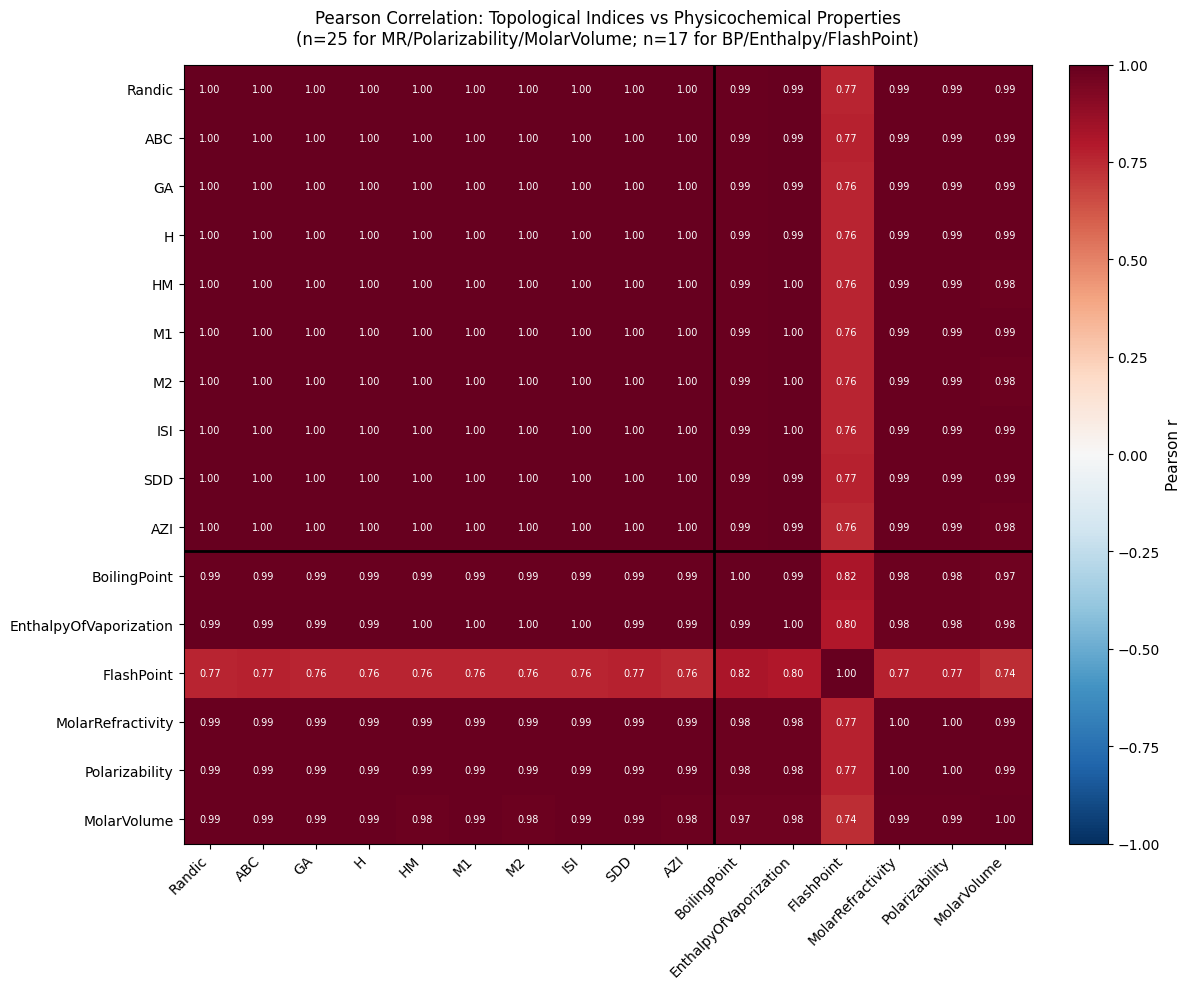


Figures/results saved to /content/drive/MyDrive/QSPR_Anthelmintic_repo/figures/ and /content/drive/MyDrive/QSPR_Anthelmintic_repo/results/

TI vs TI (n=25): min r = 0.9959, max r = 0.9999


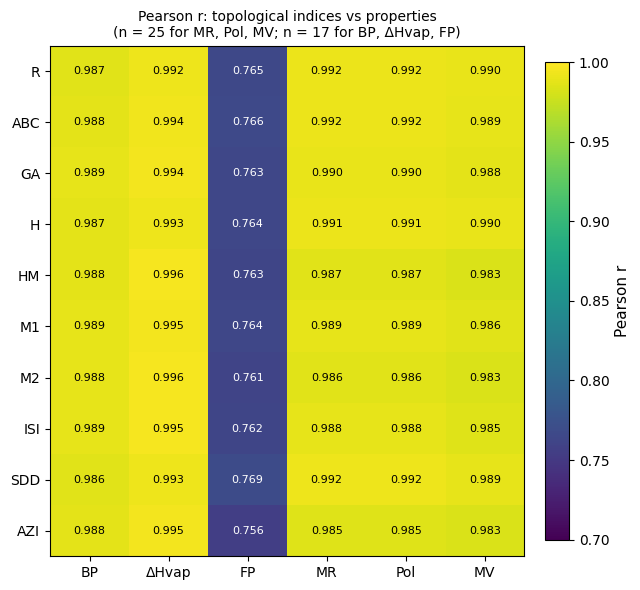


Figures/results saved to /content/drive/MyDrive/QSPR_Anthelmintic_repo/figures/ and /content/drive/MyDrive/QSPR_Anthelmintic_repo/results/


In [4]:
# ============================================================
# CELL 4: Descriptive Statistics + Pearson Correlation Heatmap
# ============================================================

import matplotlib.pyplot as plt
import matplotlib
from scipy import stats as scipy_stats

TI_COLS = ['Randic', 'ABC', 'GA', 'H', 'HM', 'M1', 'M2', 'ISI', 'SDD', 'AZI']
PROPERTY_COLS = ['BoilingPoint', 'EnthalpyOfVaporization', 'FlashPoint',
                  'MolarRefractivity', 'Polarizability', 'MolarVolume']

# --- Descriptive statistics table (n varies per property due to missing data) ---
desc_rows = []
for col in TI_COLS + PROPERTY_COLS:
    series = merged_df[col].dropna()
    desc_rows.append({
        'Variable': col, 'N': series.count(), 'Mean': series.mean(),
        'SD': series.std(), 'Min': series.min(), 'Max': series.max(),
        'Skewness': scipy_stats.skew(series)
    })
desc_df = pd.DataFrame(desc_rows)
desc_df.to_csv(f'{PROJECT_DIR}/results/descriptive_statistics.csv', index=False)
print("=== Descriptive Statistics ===")
print(desc_df.round(3).to_string(index=False))

# --- Pearson correlation matrix: TIs vs TIs, and TIs vs Properties ---
# Use pairwise-complete correlations (handles the missing BP/Enthalpy/FlashPoint values)
corr_cols = TI_COLS + PROPERTY_COLS
corr_matrix = merged_df[corr_cols].corr(method='pearson')  # pandas .corr() is pairwise-complete by default

corr_matrix.to_csv(f'{PROJECT_DIR}/results/pearson_correlation_matrix.csv')

# --- Also compute exact per-pair sample sizes (important since 3 properties have n=17, not 25) ---
n_pairs = pd.DataFrame(index=corr_cols, columns=corr_cols, dtype=int)
for c1 in corr_cols:
    for c2 in corr_cols:
        n_pairs.loc[c1, c2] = merged_df[[c1, c2]].dropna().shape[0]
n_pairs.to_csv(f'{PROJECT_DIR}/results/correlation_pairwise_n.csv')
print("\n=== Pairwise N for TI vs BoilingPoint/Enthalpy/FlashPoint correlations ===")
print(n_pairs.loc[TI_COLS, ['BoilingPoint', 'EnthalpyOfVaporization', 'FlashPoint']])

# --- Heatmap ---
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr_matrix.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')

ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(corr_cols, fontsize=10)

# Annotate cells with r values
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        r_val = corr_matrix.values[i, j]
        text_color = 'white' if abs(r_val) > 0.6 else 'black'
        ax.text(j, i, f'{r_val:.2f}', ha='center', va='center',
                color=text_color, fontsize=7)

# Visual separator between TI block and Property block
n_ti = len(TI_COLS)
ax.axhline(n_ti - 0.5, color='black', linewidth=2)
ax.axvline(n_ti - 0.5, color='black', linewidth=2)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson r", fontsize=11)

ax.set_title("Pearson Correlation: Topological Indices vs Physicochemical Properties\n"
              "(n=25 for MR/Polarizability/MolarVolume; n=17 for BP/Enthalpy/FlashPoint)",
              fontsize=12, pad=15)

plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/pearson_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nFigures/results saved to {PROJECT_DIR}/figures/ and {PROJECT_DIR}/results/")
# --- Index-vs-index summary (for the text) ---
ti_block = corr_matrix.loc[TI_COLS, TI_COLS].to_numpy()
off = ti_block[~np.eye(len(TI_COLS), dtype=bool)]
print(f"\nTI vs TI (n=25): min r = {off.min():.4f}, max r = {off.max():.4f}")

# --- Heatmap: indices vs properties (the informative block) ---
LABELS = {'Randic': 'R', 'BoilingPoint': 'BP', 'EnthalpyOfVaporization': 'ΔHvap', 'FlashPoint': 'FP',
          'MolarRefractivity': 'MR', 'Polarizability': 'Pol', 'MolarVolume': 'MV'}
block = corr_matrix.loc[TI_COLS, PROPERTY_COLS]
fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(block.values, cmap='viridis', vmin=0.7, vmax=1.0, aspect='auto')
ax.set_xticks(range(len(PROPERTY_COLS))); ax.set_xticklabels([LABELS[c] for c in PROPERTY_COLS], fontsize=10)
ax.set_yticks(range(len(TI_COLS)));       ax.set_yticklabels([LABELS.get(c, c) for c in TI_COLS], fontsize=10)
for i in range(block.shape[0]):
    for j in range(block.shape[1]):
        v = block.values[i, j]
        ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=8, color='white' if v < 0.88 else 'black')
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cbar.set_label('Pearson r', fontsize=11)
ax.set_title('Pearson r: topological indices vs properties\n(n = 25 for MR, Pol, MV; n = 17 for BP, ΔHvap, FP)', fontsize=10)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/pearson_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"\nFigures/results saved to {PROJECT_DIR}/figures/ and {PROJECT_DIR}/results/")

In [5]:
# ============================================================
# CELL 5: Simple Linear Regression — Best Single TI per Property
# LOO-CV validated (R², Q², RMSE, F-statistic, p-value, slope, intercept)
# ============================================================

from scipy import stats as scipy_stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
import numpy as np
import pandas as pd

def simple_linear_fit_stats(x, y):
    """Full-sample OLS stats for a single predictor: slope, intercept, R2, F, p."""
    n = len(x)
    slope, intercept, r_value, p_value_corr, std_err = scipy_stats.linregress(x, y)
    r2 = r_value ** 2
    # F-statistic for simple linear regression (1 predictor): F = R2/(1-R2) * (n-2)
    if r2 < 1.0:
        f_stat = (r2 / (1 - r2)) * (n - 2)
        p_value_f = scipy_stats.f.sf(f_stat, 1, n - 2)
    else:
        f_stat, p_value_f = np.inf, 0.0
    return {'slope': slope, 'intercept': intercept, 'R2': r2,
            'F': f_stat, 'p_value': p_value_f, 'n': n}

def loo_cv_simple(x, y):
    """LOO-CV for simple linear regression -> Q2 and RMSE_cv."""
    x = np.asarray(x).reshape(-1, 1)
    y = np.asarray(y)
    n = len(y)
    loo = LeaveOneOut()
    y_pred_cv = np.zeros(n)

    for train_idx, test_idx in loo.split(x):
        model = LinearRegression()
        model.fit(x[train_idx], y[train_idx])
        y_pred_cv[test_idx] = model.predict(x[test_idx])

    press = np.sum((y - y_pred_cv) ** 2)
    sst = np.sum((y - np.mean(y)) ** 2)
    q2 = 1 - press / sst
    rmse_cv = np.sqrt(press / n)
    return q2, rmse_cv, y_pred_cv

TI_COLS = ['Randic', 'ABC', 'GA', 'H', 'HM', 'M1', 'M2', 'ISI', 'SDD', 'AZI']
PROPERTY_COLS = ['BoilingPoint', 'EnthalpyOfVaporization', 'FlashPoint',
                  'MolarRefractivity', 'Polarizability', 'MolarVolume']

slr_results = []       # summary table (best TI per property)
slr_all_candidates = []  # every TI tried, for transparency/appendix
slr_loo_predictions = {}  # property -> (y_true, y_pred_cv, drug_names) for plotting later

for prop in PROPERTY_COLS:
    sub = merged_df[['Drug', prop] + TI_COLS].dropna(subset=[prop]).reset_index(drop=True)
    n = len(sub)
    y = sub[prop].values

    candidates = []
    for ti in TI_COLS:
        x = sub[ti].values
        fit = simple_linear_fit_stats(x, y)
        q2, rmse_cv, y_pred_cv = loo_cv_simple(x, y)
        candidates.append({
            'Property': prop, 'TI': ti, 'n': n,
            'R2': fit['R2'], 'Q2': q2, 'RMSE_CV': rmse_cv,
            'F': fit['F'], 'p_value': fit['p_value'],
            'slope': fit['slope'], 'intercept': fit['intercept']
        })
    cand_df = pd.DataFrame(candidates).sort_values('R2', ascending=False).reset_index(drop=True)
    slr_all_candidates.append(cand_df)

    # Select best TI by highest R2 (standard SLR selection criterion)
    best = cand_df.iloc[0]
    meets_criteria = (best['R2'] > 0.85) and (best['Q2'] > 0.80) and ((best['R2'] - best['Q2']) < 0.10)

    slr_results.append({
        'Property': prop, 'Best_TI': best['TI'], 'n': n,
        'R2': best['R2'], 'Q2': best['Q2'], 'R2_minus_Q2': best['R2'] - best['Q2'],
        'RMSE_CV': best['RMSE_CV'], 'F': best['F'], 'p_value': best['p_value'],
        'slope': best['slope'], 'intercept': best['intercept'],
        'Meets_Criteria': meets_criteria
    })

    # Store LOO predictions for the best TI (for later scatter plots)
    x_best = sub[best['TI']].values
    _, _, y_pred_cv_best = loo_cv_simple(x_best, y)
    slr_loo_predictions[prop] = {
        'Drug': sub['Drug'].values, 'y_true': y, 'y_pred_cv': y_pred_cv_best,
        'best_TI': best['TI']
    }

    print(f"\n=== {prop} (n={n}) ===")
    print(f"Best single TI: {best['TI']}")
    print(f"  R2={best['R2']:.4f}  Q2={best['Q2']:.4f}  R2-Q2={best['R2']-best['Q2']:.4f}")
    print(f"  RMSE_CV={best['RMSE_CV']:.4f}  F={best['F']:.3f}  p={best['p_value']:.2e}")
    print(f"  y = {best['slope']:.5f} * {best['TI']} + {best['intercept']:.5f}")
    print(f"  Meets validation criteria (R2>0.85, Q2>0.80, R2-Q2<0.10): {meets_criteria}")

slr_summary_df = pd.DataFrame(slr_results)
slr_all_candidates_df = pd.concat(slr_all_candidates, ignore_index=True)

slr_summary_df.to_csv(f'{PROJECT_DIR}/results/SLR_best_TI_summary.csv', index=False)
slr_all_candidates_df.to_csv(f'{PROJECT_DIR}/results/SLR_all_candidates.csv', index=False)

print("\n\n=== SLR Summary Table (best TI per property) ===")
print(slr_summary_df.round(4).to_string(index=False))


=== BoilingPoint (n=17) ===
Best single TI: ISI
  R2=0.9781  Q2=0.9720  R2-Q2=0.0061
  RMSE_CV=39.8186  F=670.326  p=7.28e-14
  y = 9.61254 * ISI + 205.72736
  Meets validation criteria (R2>0.85, Q2>0.80, R2-Q2<0.10): True

=== EnthalpyOfVaporization (n=17) ===
Best single TI: M2
  R2=0.9918  Q2=0.9891  R2-Q2=0.0028
  RMSE_CV=4.0646  F=1816.576  p=4.55e-17
  y = 0.29823 * M2 + 35.93943
  Meets validation criteria (R2>0.85, Q2>0.80, R2-Q2<0.10): True

=== FlashPoint (n=17) ===
Best single TI: SDD
  R2=0.5907  Q2=0.3696  R2-Q2=0.2211
  RMSE_CV=95.1329  F=21.647  p=3.13e-04
  y = 1.86198 * SDD + 126.20806
  Meets validation criteria (R2>0.85, Q2>0.80, R2-Q2<0.10): False

=== MolarRefractivity (n=25) ===
Best single TI: SDD
  R2=0.9843  Q2=0.9826  R2-Q2=0.0017
  RMSE_CV=7.7111  F=1439.094  p=3.04e-22
  y = 1.35061 * SDD + 15.28190
  Meets validation criteria (R2>0.85, Q2>0.80, R2-Q2<0.10): True

=== Polarizability (n=25) ===
Best single TI: SDD
  R2=0.9843  Q2=0.9826  R2-Q2=0.0017
  RMSE_

In [6]:
# ============================================================
# CELL 5b: SLR results for ALL ten indices (supplementary matrices)
# ============================================================
import pandas as pd
import numpy as np

selected = dict(zip(slr_summary_df['Property'], slr_summary_df['Best_TI']))

R2_mat = slr_all_candidates_df.pivot(index='TI', columns='Property', values='R2').loc[TI_COLS, PROPERTY_COLS]
Q2_mat = slr_all_candidates_df.pivot(index='TI', columns='Property', values='Q2').loc[TI_COLS, PROPERTY_COLS]

R2_mat.round(6).to_csv(f'{PROJECT_DIR}/results/SLR_R2_matrix.csv')
Q2_mat.round(6).to_csv(f'{PROJECT_DIR}/results/SLR_Q2_matrix.csv')

# Long table with ranks and distance to the best index
rank_df = slr_all_candidates_df.copy()
rank_df['Selected'] = [selected[p] == t for p, t in zip(rank_df['Property'], rank_df['TI'])]
rank_df['Rank_R2'] = rank_df.groupby('Property')['R2'].rank(ascending=False, method='min').astype(int)
rank_df['Rank_Q2'] = rank_df.groupby('Property')['Q2'].rank(ascending=False, method='min').astype(int)
rank_df['dQ2_to_best_Q2'] = rank_df['Q2'] - rank_df.groupby('Property')['Q2'].transform('max')
rank_df['Meets_Criteria'] = (rank_df['R2'] > 0.85) & (rank_df['Q2'] > 0.80) & ((rank_df['R2'] - rank_df['Q2']) < 0.10)
rank_df.to_csv(f'{PROJECT_DIR}/results/SLR_index_ranking.csv', index=False)

# Display copies with the selected index marked by *
def marked(mat):
    out = mat.round(4).astype(str)
    for p, t in selected.items():
        out.loc[t, p] = out.loc[t, p] + '*'
    return out

print("=== R2 (rows = index; * = index selected by highest R2) ===")
print(marked(R2_mat).to_string())
print("\n=== Q2 (LOO-CV) ===")
print(marked(Q2_mat).to_string())

print("\n=== How many indices are practically tied with the best? ===")
for p in PROPERTY_COLS:
    s = rank_df[rank_df['Property'] == p]
    best_q2_ti = s.loc[s['Q2'].idxmax(), 'TI']
    n_close = int((s['dQ2_to_best_Q2'] >= -0.01).sum())
    n_ok = int(s['Meets_Criteria'].sum())
    print(f"{p:24s} selected (max R2) = {selected[p]:7s} | max Q2 = {best_q2_ti:7s} | "
          f"indices within 0.01 Q2 of best: {n_close}/10 | meet criteria: {n_ok}/10")

=== R2 (rows = index; * = index selected by highest R2) ===
Property BoilingPoint EnthalpyOfVaporization FlashPoint MolarRefractivity Polarizability MolarVolume
TI                                                                                                  
Randic         0.9739                  0.985     0.5853            0.9832         0.9832     0.9805*
ABC            0.9764                 0.9874     0.5872            0.9831         0.9832      0.9779
GA             0.9774                 0.9885     0.5828            0.9801         0.9802      0.9755
H              0.9747                 0.9855     0.5833            0.9816         0.9817      0.9794
HM             0.9761                 0.9917     0.5817            0.9736         0.9737      0.9669
M1             0.9774                 0.9905     0.5839            0.9786         0.9787      0.9724
M2             0.9767                0.9918*     0.5792            0.9723         0.9723      0.9654
ISI           0.9781*          

Forward stepwise regression

In [7]:
# ============================================================
# CELL 6: Forward Stepwise Linear Regression
# alpha=0.01, max 3 predictors, LOO-CV validated
# ============================================================

import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
import numpy as np
import pandas as pd

ALPHA = 0.01
MAX_PREDICTORS = 3

def forward_stepwise_select(X_df, y, alpha=ALPHA, max_predictors=MAX_PREDICTORS):
    """
    Forward selection: at each step, add the candidate predictor that most
    improves the model AND whose entry p-value < alpha. Stop when no
    remaining candidate qualifies, or max_predictors reached.
    Returns: list of selected column names, in order of entry.
    """
    remaining = list(X_df.columns)
    selected = []
    n = len(y)

    while remaining and len(selected) < max_predictors:
        best_candidate = None
        best_p = 1.0
        best_r2 = -np.inf

        for candidate in remaining:
            trial_cols = selected + [candidate]
            X_trial = sm.add_constant(X_df[trial_cols].values)
            model = sm.OLS(y, X_trial).fit()
            # p-value of the newly added predictor (last coefficient)
            p_new = model.pvalues[-1]
            r2_trial = model.rsquared

            # Guard: reject if adding this predictor causes severe multicollinearity
            # (VIF check) -- skip candidate if any VIF > 10 among selected+candidate
            if len(trial_cols) > 1:
                corr_sub = X_df[trial_cols].corr().values
                try:
                    vif_flag = np.any(np.linalg.inv(corr_sub).diagonal() > 10)
                except np.linalg.LinAlgError:
                    vif_flag = True  # singular -> treat as multicollinear, reject
            else:
                vif_flag = False

            if p_new < alpha and not vif_flag and r2_trial > best_r2:
                best_r2 = r2_trial
                best_p = p_new
                best_candidate = candidate

        if best_candidate is None:
            break  # no remaining candidate meets alpha threshold
        selected.append(best_candidate)
        remaining.remove(best_candidate)

    return selected

def loo_cv_multivariate(X, y):
    """LOO-CV for multivariate linear regression -> Q2 and RMSE_cv."""
    X = np.asarray(X)
    y = np.asarray(y)
    n = len(y)
    loo = LeaveOneOut()
    y_pred_cv = np.zeros(n)

    for train_idx, test_idx in loo.split(X):
        model = LinearRegression()
        model.fit(X[train_idx], y[train_idx])
        y_pred_cv[test_idx] = model.predict(X[test_idx])

    press = np.sum((y - y_pred_cv) ** 2)
    sst = np.sum((y - np.mean(y)) ** 2)
    q2 = 1 - press / sst
    rmse_cv = np.sqrt(press / n)
    return q2, rmse_cv, y_pred_cv

stepwise_results = []
stepwise_loo_predictions = {}

for prop in PROPERTY_COLS:
    sub = merged_df[['Drug', prop] + TI_COLS].dropna(subset=[prop]).reset_index(drop=True)
    n = len(sub)
    y = sub[prop].values
    X_df = sub[TI_COLS]

    selected_tis = forward_stepwise_select(X_df, y)

    if not selected_tis:
        print(f"\n=== {prop} (n={n}) ===")
        print("No predictor met entry threshold (alpha=0.01). No model fit.")
        stepwise_results.append({
            'Property': prop, 'n': n, 'Selected_TIs': 'None',
            'Num_Predictors': 0, 'R2': np.nan, 'Q2': np.nan,
            'R2_minus_Q2': np.nan, 'RMSE_CV': np.nan, 'F': np.nan,
            'p_value': np.nan, 'Meets_Criteria': False
        })
        continue

    X_final = X_df[selected_tis].values
    X_final_sm = sm.add_constant(X_final)
    final_model = sm.OLS(y, X_final_sm).fit()

    r2 = final_model.rsquared
    f_stat = final_model.fvalue
    p_value = final_model.f_pvalue

    q2, rmse_cv, y_pred_cv = loo_cv_multivariate(X_final, y)
    r2_minus_q2 = r2 - q2
    meets_criteria = (r2 > 0.85) and (q2 > 0.80) and (r2_minus_q2 < 0.10)

    stepwise_results.append({
        'Property': prop, 'n': n, 'Selected_TIs': ', '.join(selected_tis),
        'Num_Predictors': len(selected_tis), 'R2': r2, 'Q2': q2,
        'R2_minus_Q2': r2_minus_q2, 'RMSE_CV': rmse_cv,
        'F': f_stat, 'p_value': p_value, 'Meets_Criteria': meets_criteria
    })

    stepwise_loo_predictions[prop] = {
        'Drug': sub['Drug'].values, 'y_true': y, 'y_pred_cv': y_pred_cv,
        'selected_TIs': selected_tis
    }

    print(f"\n=== {prop} (n={n}) ===")
    print(f"Selected TIs (entry order): {selected_tis}")
    print(f"  R2={r2:.4f}  Q2={q2:.4f}  R2-Q2={r2_minus_q2:.4f}")
    print(f"  RMSE_CV={rmse_cv:.4f}  F={f_stat:.3f}  p={p_value:.2e}")
    print(f"  Coefficients: const={final_model.params[0]:.5f}, " +
          ", ".join([f"{t}={c:.5f}" for t, c in zip(selected_tis, final_model.params[1:])]))
    print(f"  Meets validation criteria (R2>0.85, Q2>0.80, R2-Q2<0.10): {meets_criteria}")

stepwise_summary_df = pd.DataFrame(stepwise_results)
stepwise_summary_df.to_csv(f'{PROJECT_DIR}/results/stepwise_LR_summary.csv', index=False)

print("\n\n=== Forward Stepwise Regression Summary ===")
print(stepwise_summary_df.round(4).to_string(index=False))


=== BoilingPoint (n=17) ===
Selected TIs (entry order): ['ISI']
  R2=0.9781  Q2=0.9720  R2-Q2=0.0061
  RMSE_CV=39.8186  F=670.326  p=7.28e-14
  Coefficients: const=205.72736, ISI=9.61254
  Meets validation criteria (R2>0.85, Q2>0.80, R2-Q2<0.10): True

=== EnthalpyOfVaporization (n=17) ===
Selected TIs (entry order): ['M2']
  R2=0.9918  Q2=0.9891  R2-Q2=0.0028
  RMSE_CV=4.0646  F=1816.576  p=4.55e-17
  Coefficients: const=35.93943, M2=0.29823
  Meets validation criteria (R2>0.85, Q2>0.80, R2-Q2<0.10): True

=== FlashPoint (n=17) ===
Selected TIs (entry order): ['SDD']
  R2=0.5907  Q2=0.3696  R2-Q2=0.2211
  RMSE_CV=95.1329  F=21.647  p=3.13e-04
  Coefficients: const=126.20806, SDD=1.86198
  Meets validation criteria (R2>0.85, Q2>0.80, R2-Q2<0.10): False

=== MolarRefractivity (n=25) ===
Selected TIs (entry order): ['SDD']
  R2=0.9843  Q2=0.9826  R2-Q2=0.0017
  RMSE_CV=7.7111  F=1439.094  p=3.04e-22
  Coefficients: const=15.28190, SDD=1.35061
  Meets validation criteria (R2>0.85, Q2>0.8

Stepwise diagnostics: why no second index enters

In [8]:
def forward_stepwise_logged(X_df, y, prop, alpha=ALPHA, max_predictors=MAX_PREDICTORS, vif_limit=10):
    remaining, selected, log, step = list(X_df.columns), [], [], 0
    while remaining and len(selected) < max_predictors:
        step += 1
        best_candidate, best_r2 = None, -np.inf
        for cand in remaining:
            trial = selected + [cand]
            model = sm.OLS(y, sm.add_constant(X_df[trial].values)).fit()
            p_new, r2_trial = model.pvalues[-1], model.rsquared
            if len(trial) > 1:
                corr_sub = X_df[trial].corr().values
                try:
                    vifs = np.linalg.inv(corr_sub).diagonal()
                    vif_cand, vif_worst = vifs[-1], vifs.max()
                except np.linalg.LinAlgError:
                    vif_cand = vif_worst = np.inf
                r_with_sel = np.abs(corr_sub[-1, :-1]).max()
            else:
                vif_cand = vif_worst = 1.0; r_with_sel = np.nan
            ok_p, ok_vif = p_new < alpha, vif_worst <= vif_limit
            log.append(dict(Property=prop, step=step, selected_so_far='+'.join(selected) or '(none)',
                            candidate=cand, r_with_selected=r_with_sel, p_entry=p_new,
                            VIF_candidate=vif_cand, VIF_max=vif_worst, R2=r2_trial,
                            passes_p=ok_p, passes_VIF=ok_vif, entered=False))
            if ok_p and ok_vif and r2_trial > best_r2:
                best_r2, best_candidate = r2_trial, cand
        if best_candidate is None:
            break
        for row in log:
            if row['step'] == step and row['candidate'] == best_candidate:
                row['entered'] = True
        selected.append(best_candidate); remaining.remove(best_candidate)
    return selected, log

all_log, corr_rows, summ_rows = [], [], []
for prop in PROPERTY_COLS:
    sub = merged_df[['Drug', prop] + TI_COLS].dropna(subset=[prop]).reset_index(drop=True)
    X_df, y = sub[TI_COLS], sub[prop].values
    sel, log = forward_stepwise_logged(X_df, y, prop)

    # the logged version must agree with Cell 6
    expected = stepwise_summary_df.loc[stepwise_summary_df.Property == prop, 'Selected_TIs'].iloc[0]
    assert ', '.join(sel) == expected, f'{prop}: {sel} vs {expected}'

    all_log += log
    C = X_df.corr().to_numpy(); off = C[~np.eye(len(TI_COLS), dtype=bool)]
    corr_rows.append(dict(Property=prop, n=len(y), min_pairwise_r=off.min(), max_pairwise_r=off.max()))

    step2 = pd.DataFrame([r for r in log if r['step'] == 2])
    if len(step2):
        b = step2.loc[step2.p_entry.idxmin()]
        summ_rows.append(dict(Property=prop, n=len(y), first_TI=sel[0], n_candidates=len(step2),
                              n_pass_p=int(step2.passes_p.sum()), n_pass_VIF=int(step2.passes_VIF.sum()),
                              min_VIF=step2.VIF_candidate.min(),
                              lowest_p_candidate=b['candidate'], its_p=b['p_entry'], its_VIF=b['VIF_candidate'],
                              reason=('p >= 0.01 and VIF > 10' if (not b['passes_p'] and not b['passes_VIF'])
                                      else 'p >= 0.01' if not b['passes_p'] else 'VIF > 10')))

log_df = pd.DataFrame(all_log); summ_df = pd.DataFrame(summ_rows); corr_df = pd.DataFrame(corr_rows)
log_df.to_csv(f'{PROJECT_DIR}/results/stepwise_all_candidates.csv', index=False)
summ_df.to_csv(f'{PROJECT_DIR}/results/stepwise_vif_summary.csv', index=False)
corr_df.to_csv(f'{PROJECT_DIR}/results/stepwise_index_correlations.csv', index=False)

print('=== correlation among the ten indices (per compound set) ===')
print(corr_df.round(4).to_string(index=False))
print('\n=== why no second index entered (step 2) ===')
s = summ_df.copy(); s['its_p'] = s['its_p'].map(lambda v: f'{v:.1e}')
print(s.round(2).to_string(index=False))
print('\nAll properties agree with Cell 6.')

=== correlation among the ten indices (per compound set) ===
              Property  n  min_pairwise_r  max_pairwise_r
          BoilingPoint 17          0.9961          0.9999
EnthalpyOfVaporization 17          0.9961          0.9999
            FlashPoint 17          0.9961          0.9999
     MolarRefractivity 25          0.9959          0.9999
        Polarizability 25          0.9959          0.9999
           MolarVolume 25          0.9959          0.9999

=== why no second index entered (step 2) ===
              Property  n first_TI  n_candidates  n_pass_p  n_pass_VIF  min_VIF lowest_p_candidate   its_p  its_VIF                 reason
          BoilingPoint 17      ISI             9         0           0   273.54                AZI 5.8e-01  1056.06 p >= 0.01 and VIF > 10
EnthalpyOfVaporization 17       M2             9         0           0   210.83             Randic 5.0e-01   215.64 p >= 0.01 and VIF > 10
            FlashPoint 17      SDD             9         0           0

Nested LOO-CV; inner 5-fold shuffled CV (seed 42), MSE scoring; grid C {10, 50, 100, 500}, ε {0.1, 0.2, 0.3, 0.5}, γ {scale, auto}

In [9]:
# ============================================================
# CELL 7: SVR (RBF kernel) — GridSearchCV nested inside LOO-CV
# Hyperparameter tuning done INSIDE each fold to prevent data leakage
# Inner CV: 5-fold shuffled (seed 42), MSE scoring
# Grid: C {10,50,100,500}, epsilon {0.1,0.2,0.3,0.5}, gamma {scale,auto}
# ============================================================

from sklearn.svm import SVR
from sklearn.model_selection import LeaveOneOut, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

PARAM_GRID = {
    'svr__C': [10, 50, 100, 500],
    'svr__epsilon': [0.1, 0.2, 0.3, 0.5],
    'svr__gamma': ['scale', 'auto']
}

def svr_loo_cv_nested(X, y, param_grid=PARAM_GRID, inner_cv_splits=5, random_state=42):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(y)
    loo = LeaveOneOut()
    y_pred_cv = np.zeros(n)
    fold_best_params = []

    inner_splits = min(inner_cv_splits, n - 1)
    inner_splits = max(inner_splits, 2)

    for train_idx, test_idx in loo.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('svr', SVR(kernel='rbf'))
        ])
        inner_cv = KFold(n_splits=inner_splits, shuffle=True, random_state=random_state)
        grid = GridSearchCV(pipe, param_grid, cv=inner_cv,
                            scoring='neg_mean_squared_error', n_jobs=-1)
        grid.fit(X_train, y_train)

        y_pred_cv[test_idx] = grid.predict(X_test)
        fold_best_params.append(grid.best_params_)

    press = np.sum((y - y_pred_cv) ** 2)
    sst = np.sum((y - np.mean(y)) ** 2)
    q2 = 1 - press / sst
    rmse_cv = np.sqrt(press / n)

    # Final refit on all data (NOT used for Q2; used for R2 and external validation)
    pipe_full = Pipeline([('scaler', StandardScaler()), ('svr', SVR(kernel='rbf'))])
    inner_cv_full = KFold(n_splits=min(inner_cv_splits, n), shuffle=True, random_state=random_state)
    grid_full = GridSearchCV(pipe_full, param_grid, cv=inner_cv_full,
                             scoring='neg_mean_squared_error', n_jobs=-1)
    grid_full.fit(X, y)

    return q2, rmse_cv, y_pred_cv, grid_full.best_params_, fold_best_params, grid_full.best_estimator_

TI_COLS = ['Randic', 'ABC', 'GA', 'H', 'HM', 'M1', 'M2', 'ISI', 'SDD', 'AZI']
PROPERTY_COLS = ['BoilingPoint', 'EnthalpyOfVaporization', 'FlashPoint',
                 'MolarRefractivity', 'Polarizability', 'MolarVolume']

svr_results = []
svr_loo_predictions = {}
svr_fitted_models = {}

for prop in PROPERTY_COLS:
    sub = merged_df[['Drug', prop] + TI_COLS].dropna(subset=[prop]).reset_index(drop=True)
    n = len(sub)
    y = sub[prop].values

    best_ti = slr_summary_df.loc[slr_summary_df['Property'] == prop, 'Best_TI'].values[0]
    X = sub[[best_ti]].values

    print(f"\n=== {prop} (n={n}, predictor={best_ti}) ===")
    q2, rmse_cv, y_pred_cv, best_params, fold_params, fitted_model = svr_loo_cv_nested(X, y)
    r2_fit = fitted_model.score(X, y)
    meets = (r2_fit > 0.85) and (q2 > 0.80) and ((r2_fit - q2) < 0.10)

    svr_results.append({
        'Property': prop, 'n': n, 'Predictor_TI': best_ti,
        'Q2': q2, 'RMSE_CV': rmse_cv,
        'Best_C': best_params['svr__C'], 'Best_epsilon': best_params['svr__epsilon'],
        'Best_gamma': best_params['svr__gamma'],
        'R2': r2_fit, 'R2_minus_Q2': r2_fit - q2, 'Meets_Criteria': meets
    })

    svr_loo_predictions[prop] = {
        'Drug': sub['Drug'].values, 'y_true': y, 'y_pred_cv': y_pred_cv,
        'predictor_TI': best_ti
    }
    svr_fitted_models[prop] = {'model': fitted_model, 'predictor_TI': best_ti}

    print(f"  Q2={q2:.4f}  RMSE_CV={rmse_cv:.4f}")
    print(f"  Representative best params (full-data refit): {best_params}")
    c_vals = [p['svr__C'] for p in fold_params]
    print(f"  Hyperparam stability across {n} LOO folds: C range=[{min(c_vals)},{max(c_vals)}], "
          f"unique param combos={len(set(tuple(sorted(p.items())) for p in fold_params))}")

svr_summary_df = pd.DataFrame(svr_results)
svr_summary_df.to_csv(f'{PROJECT_DIR}/results/SVR_summary.csv', index=False)

print("\n\n=== SVR (RBF) Summary Table ===")
print(svr_summary_df.round(4).to_string(index=False))

svr_pred_df = pd.concat([pd.DataFrame({'Property': p, 'Drug': v['Drug'], 'y_true': v['y_true'],
                                       'y_pred_cv': v['y_pred_cv'], 'predictor_TI': v['predictor_TI']})
                         for p, v in svr_loo_predictions.items()], ignore_index=True)
svr_pred_df.to_csv(f'{PROJECT_DIR}/results/SVR_loo_predictions.csv', index=False)

cmp_df = svr_summary_df.merge(slr_summary_df[['Property', 'Q2', 'RMSE_CV']].rename(
             columns={'Q2': 'Q2_SLR', 'RMSE_CV': 'RMSE_CV_SLR'}), on='Property')
cmp_df['dQ2_SVR_minus_SLR'] = cmp_df['Q2'] - cmp_df['Q2_SLR']
cmp_df.to_csv(f'{PROJECT_DIR}/results/SLR_vs_SVR_comparison.csv', index=False)

print("\n=== SLR vs SVR ===")
print(cmp_df[['Property', 'Predictor_TI', 'Q2_SLR', 'Q2', 'dQ2_SVR_minus_SLR',
              'R2', 'R2_minus_Q2', 'Meets_Criteria']].round(4).to_string(index=False))


=== BoilingPoint (n=17, predictor=ISI) ===
  Q2=0.9785  RMSE_CV=34.9173
  Representative best params (full-data refit): {'svr__C': 500, 'svr__epsilon': 0.5, 'svr__gamma': 'scale'}
  Hyperparam stability across 17 LOO folds: C range=[500,500], unique param combos=4

=== EnthalpyOfVaporization (n=17, predictor=M2) ===
  Q2=0.9887  RMSE_CV=4.1274
  Representative best params (full-data refit): {'svr__C': 500, 'svr__epsilon': 0.5, 'svr__gamma': 'auto'}
  Hyperparam stability across 17 LOO folds: C range=[100,500], unique param combos=5

=== FlashPoint (n=17, predictor=SDD) ===
  Q2=0.3118  RMSE_CV=99.3927
  Representative best params (full-data refit): {'svr__C': 100, 'svr__epsilon': 0.1, 'svr__gamma': 'scale'}
  Hyperparam stability across 17 LOO folds: C range=[50,500], unique param combos=5

=== MolarRefractivity (n=25, predictor=SDD) ===
  Q2=0.9923  RMSE_CV=5.1402
  Representative best params (full-data refit): {'svr__C': 100, 'svr__epsilon': 0.5, 'svr__gamma': 'auto'}
  Hyperparam s

=== Three-Model Comparison Table ===
              Property  SLR_Q2  SLR_RMSE  Stepwise_Q2  Stepwise_RMSE  SVR_Q2  SVR_RMSE
          BoilingPoint  0.9720   39.8186       0.9720        39.8186  0.9785   34.9173
EnthalpyOfVaporization  0.9891    4.0646       0.9891         4.0646  0.9887    4.1274
            FlashPoint  0.3696   95.1329       0.3696        95.1329  0.3118   99.3927
     MolarRefractivity  0.9826    7.7111       0.9826         7.7111  0.9923    5.1402
        Polarizability  0.9826    3.0543       0.9826         3.0543  0.9925    2.0117
           MolarVolume  0.9770   27.7439       0.9770        27.7439  0.9804   25.6066


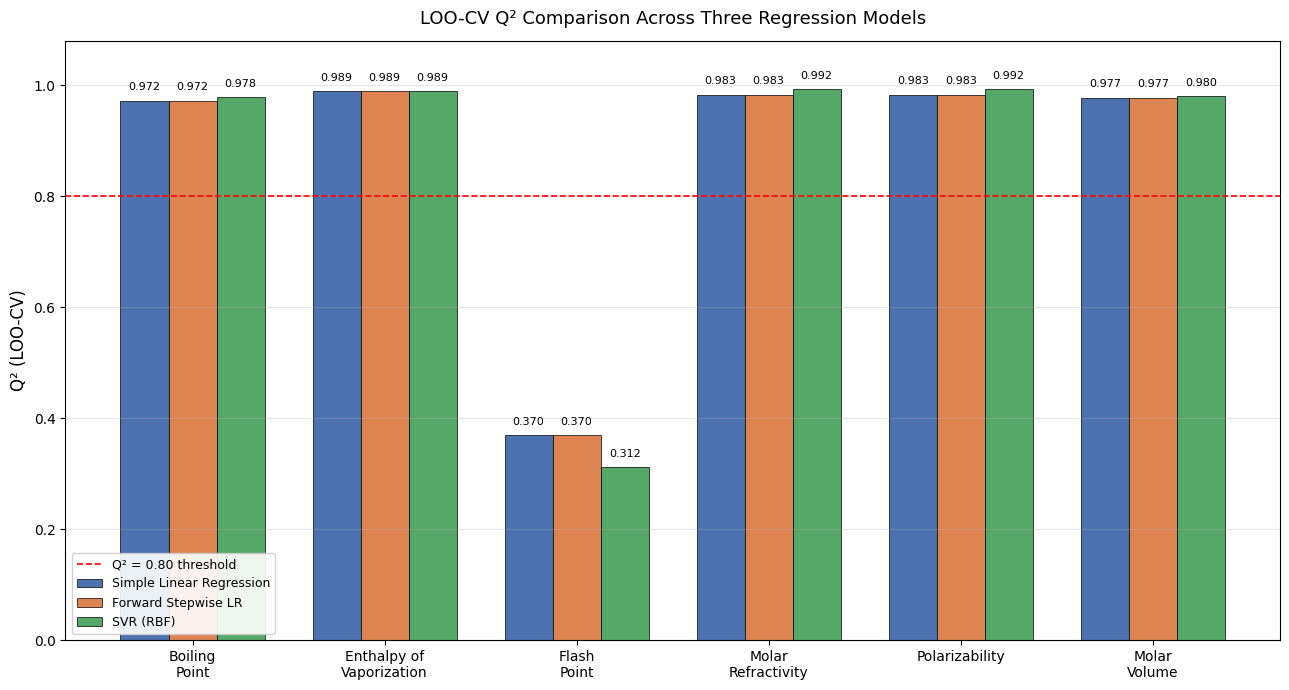

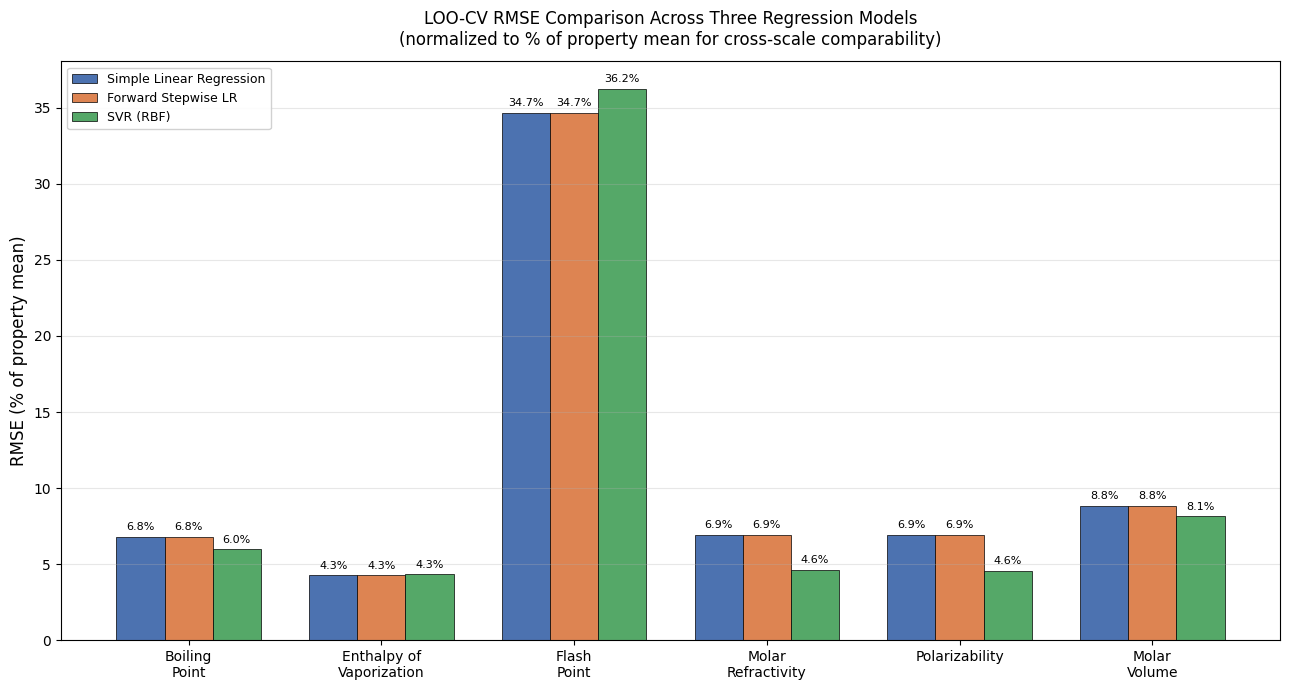

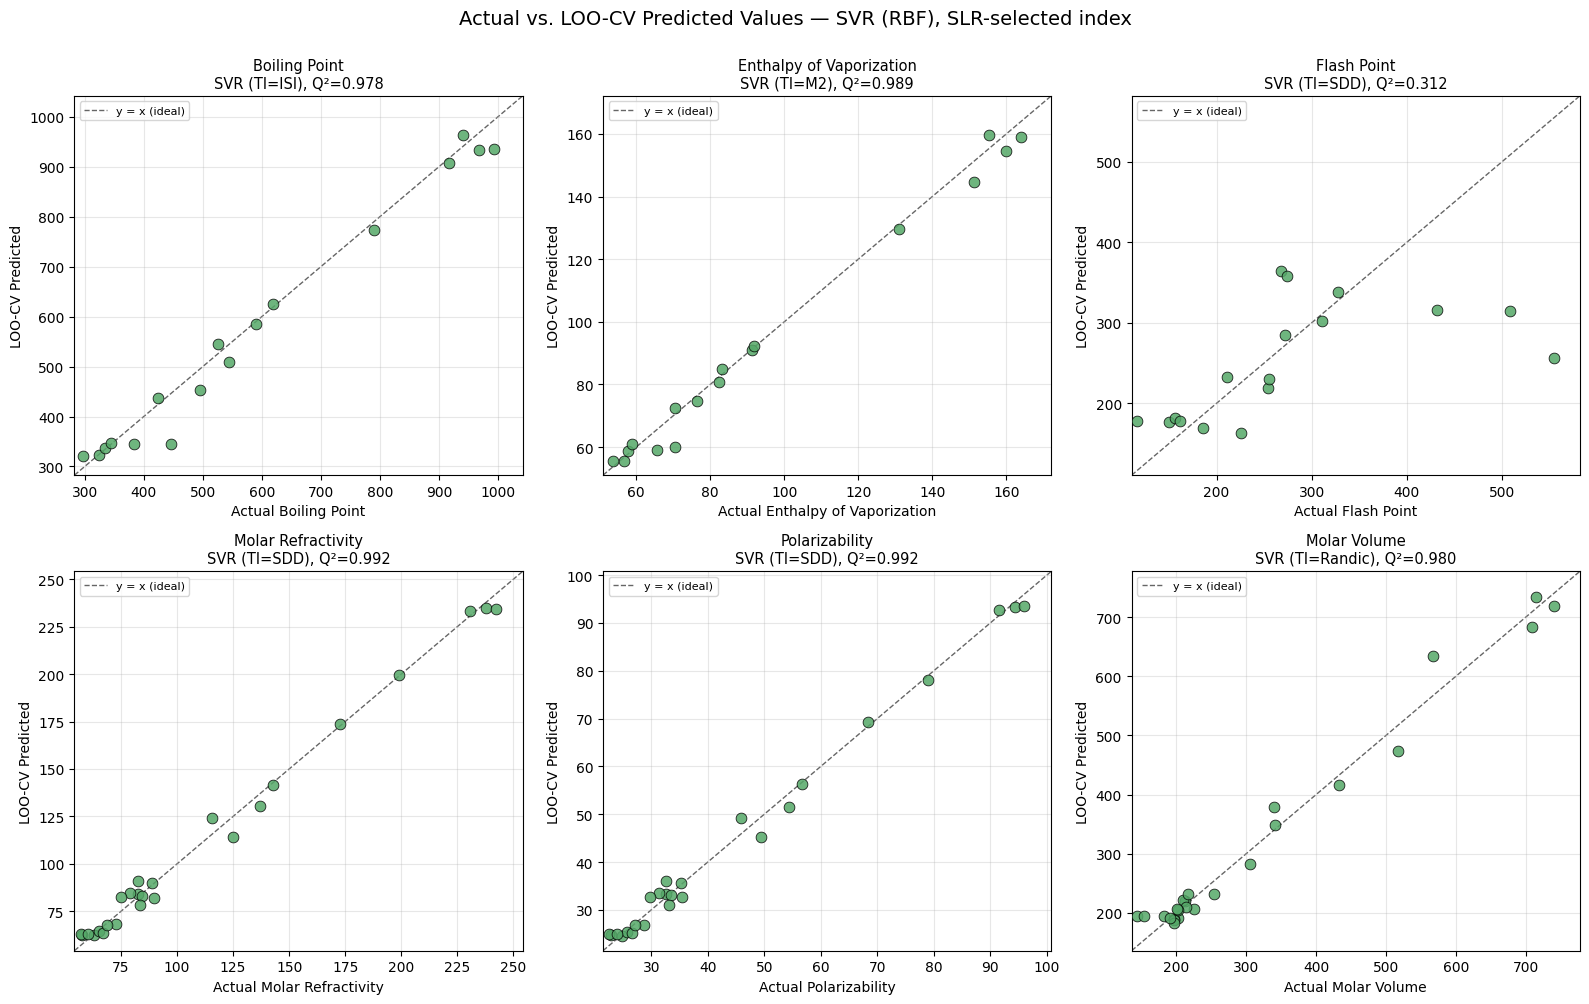


All figures saved to /content/drive/MyDrive/QSPR_Anthelmintic_repo/figures/
  - Q2_comparison_barchart.png
  - RMSE_comparison_barchart.png
  - SVR_actual_vs_predicted_scatter.png
  - pearson_correlation_heatmap.png (from Cell 4)


In [10]:
# ============================================================
# CELL 8: Publication Figures
# Q2 bar chart (3 models x 6 properties), RMSE comparison,
# Actual vs Predicted scatter for best SVR models
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROPERTY_LABELS = {
    'BoilingPoint': 'Boiling\nPoint', 'EnthalpyOfVaporization': 'Enthalpy of\nVaporization',
    'FlashPoint': 'Flash\nPoint', 'MolarRefractivity': 'Molar\nRefractivity',
    'Polarizability': 'Polarizability', 'MolarVolume': 'Molar\nVolume'
}
PROPERTY_COLS = list(PROPERTY_LABELS.keys())

# --- Assemble comparison table across all 3 models ---
comparison_rows = []
for prop in PROPERTY_COLS:
    slr_row = slr_summary_df[slr_summary_df['Property'] == prop].iloc[0]
    step_row = stepwise_summary_df[stepwise_summary_df['Property'] == prop].iloc[0]
    svr_row = svr_summary_df[svr_summary_df['Property'] == prop].iloc[0]
    comparison_rows.append({
        'Property': prop,
        'SLR_Q2': slr_row['Q2'], 'SLR_RMSE': slr_row['RMSE_CV'],
        'Stepwise_Q2': step_row['Q2'], 'Stepwise_RMSE': step_row['RMSE_CV'],
        'SVR_Q2': svr_row['Q2'], 'SVR_RMSE': svr_row['RMSE_CV'],
    })
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(f'{PROJECT_DIR}/results/model_comparison_summary.csv', index=False)
print("=== Three-Model Comparison Table ===")
print(comparison_df.round(4).to_string(index=False))

# ============================================================
# FIGURE 1: Q2 Bar Chart — three models x six properties
# ============================================================
fig, ax = plt.subplots(figsize=(13, 7))
x = np.arange(len(PROPERTY_COLS))
width = 0.25

bars1 = ax.bar(x - width, comparison_df['SLR_Q2'], width, label='Simple Linear Regression',
               color='#4C72B0', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x, comparison_df['Stepwise_Q2'], width, label='Forward Stepwise LR',
               color='#DD8452', edgecolor='black', linewidth=0.5)
bars3 = ax.bar(x + width, comparison_df['SVR_Q2'], width, label='SVR (RBF)',
               color='#55A868', edgecolor='black', linewidth=0.5)

ax.axhline(0.80, color='red', linestyle='--', linewidth=1.2, label='Q² = 0.80 threshold')

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.015, f'{h:.3f}',
                ha='center', va='bottom', fontsize=8, rotation=0)

ax.set_xticks(x)
ax.set_xticklabels([PROPERTY_LABELS[p] for p in PROPERTY_COLS], fontsize=10)
ax.set_ylabel('Q² (LOO-CV)', fontsize=12)
ax.set_title('LOO-CV Q² Comparison Across Three Regression Models', fontsize=13, pad=12)
ax.set_ylim(0, 1.08)
ax.legend(loc='lower left', fontsize=9, framealpha=0.9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/Q2_comparison_barchart.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# FIGURE 2: RMSE Comparison Chart (normalized, since properties are on different scales)
# ============================================================
# Normalize RMSE by property mean (%RMSE) for fair cross-property visual comparison
fig, ax = plt.subplots(figsize=(13, 7))

norm_slr, norm_step, norm_svr = [], [], []
for prop in PROPERTY_COLS:
    prop_mean = merged_df[prop].dropna().mean()
    row = comparison_df[comparison_df['Property'] == prop].iloc[0]
    norm_slr.append(100 * row['SLR_RMSE'] / prop_mean)
    norm_step.append(100 * row['Stepwise_RMSE'] / prop_mean)
    norm_svr.append(100 * row['SVR_RMSE'] / prop_mean)

bars1 = ax.bar(x - width, norm_slr, width, label='Simple Linear Regression',
               color='#4C72B0', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x, norm_step, width, label='Forward Stepwise LR',
               color='#DD8452', edgecolor='black', linewidth=0.5)
bars3 = ax.bar(x + width, norm_svr, width, label='SVR (RBF)',
               color='#55A868', edgecolor='black', linewidth=0.5)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.3, f'{h:.1f}%',
                ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([PROPERTY_LABELS[p] for p in PROPERTY_COLS], fontsize=10)
ax.set_ylabel('RMSE (% of property mean)', fontsize=12)
ax.set_title('LOO-CV RMSE Comparison Across Three Regression Models\n(normalized to % of property mean for cross-scale comparability)',
              fontsize=12, pad=12)
ax.legend(loc='upper left', fontsize=9, framealpha=0.9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/RMSE_comparison_barchart.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# FIGURE 3: Actual vs Predicted Scatter Plots — SVR models (all 6 properties)
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, prop in enumerate(PROPERTY_COLS):
    ax = axes[idx]
    pred_data = svr_loo_predictions[prop]
    y_true, y_pred = pred_data['y_true'], pred_data['y_pred_cv']
    q2 = svr_summary_df.loc[svr_summary_df['Property'] == prop, 'Q2'].values[0]
    ti_used = pred_data['predictor_TI']

    ax.scatter(y_true, y_pred, s=60, color='#55A868', edgecolor='black',
               linewidth=0.6, alpha=0.85, zorder=3)

    lims = [min(y_true.min(), y_pred.min()) * 0.95, max(y_true.max(), y_pred.max()) * 1.05]
    ax.plot(lims, lims, 'k--', linewidth=1, alpha=0.6, zorder=1, label='y = x (ideal)')

    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel(f'Actual {PROPERTY_LABELS[prop].replace(chr(10), " ")}', fontsize=10)
    ax.set_ylabel(f'LOO-CV Predicted', fontsize=10)
    ax.set_title(f'{PROPERTY_LABELS[prop].replace(chr(10), " ")}\nSVR (TI={ti_used}), Q²={q2:.3f}',
                 fontsize=10.5)
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('Actual vs. LOO-CV Predicted Values — SVR (RBF), SLR-selected index', fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/SVR_actual_vs_predicted_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAll figures saved to {PROJECT_DIR}/figures/")
print("  - Q2_comparison_barchart.png")
print("  - RMSE_comparison_barchart.png")
print("  - SVR_actual_vs_predicted_scatter.png")
print("  - pearson_correlation_heatmap.png (from Cell 4)")

In [11]:
# ============================================================
# CELL 9: External validation (Bunamidine, Oxyclozanide)
# Both models (SLR baseline, SVR) per property; reference values are ACD/Labs predictions
# ============================================================
import numpy as np
import pandas as pd

external = {
    'Bunamidine': {'CID': 13986, 'Formula': 'C25H38N2O',
        'BoilingPoint': 495.0, 'EnthalpyOfVaporization': 76.2, 'FlashPoint': 253.1,   # <-- verify against the xlsx
        'MolarRefractivity': 119.4, 'Polarizability': 47.3, 'MolarVolume': 389.3},
    'Oxyclozanide': {'CID': 16779, 'Formula': 'C13H6Cl5NO3',
        'BoilingPoint': 446.0, 'EnthalpyOfVaporization': 73.1, 'FlashPoint': 223.5,
        'MolarRefractivity': 89.1, 'Polarizability': 35.3, 'MolarVolume': 224.9},
}
VALID_PROPS = [p for p in PROPERTY_COLS if p != 'FlashPoint']   # flash point model failed the criteria

rows, ext_ti_cache = [], {}
for drug_name, d in external.items():
    smiles, formula = fetch_connectivity_smiles(d['CID'])
    assert '.' not in smiles, f'{drug_name}: multiple fragments in SMILES'
    assert formula.replace(' ', '') == d['Formula'], f'{drug_name}: formula {formula} != {d["Formula"]}'
    ti = compute_topological_indices(smiles)
    ext_ti_cache[drug_name] = {'SMILES': smiles, 'MolecularFormula': formula, **ti}
    print(f"{drug_name} (CID {d['CID']}): {smiles} | {formula} | heavy atoms {ti['HeavyAtoms']}")

    for prop in PROPERTY_COLS:
        ti_name = slr_summary_df.loc[slr_summary_df['Property'] == prop, 'Best_TI'].values[0]
        srow = slr_summary_df[slr_summary_df['Property'] == prop].iloc[0]
        x_val = ti[ti_name]
        preds = {'SLR': srow['slope'] * x_val + srow['intercept'],
                 'SVR': svr_fitted_models[prop]['model'].predict(np.array([[x_val]]))[0]}
        ref = d[prop]
        for model, pred in preds.items():
            rows.append({'Drug': drug_name, 'Property': prop, 'Model': model,
                         'Predictor_TI': ti_name, 'TI_Value': x_val,
                         'Predicted': pred, 'Reference_ACDLabs': ref,
                         'SignedError': pred - ref, 'SignedPctError': 100 * (pred - ref) / abs(ref),
                         'AbsPctError': 100 * abs(pred - ref) / abs(ref),
                         'Model_valid': prop in VALID_PROPS})

validation_df = pd.DataFrame(rows)
validation_df.to_csv(f'{PROJECT_DIR}/results/external_validation.csv', index=False)
pd.DataFrame(ext_ti_cache).T.to_csv(f'{PROJECT_DIR}/results/external_drugs_TIs.csv')

print("\n=== External validation: signed % error (pred - ref)/ref ===")
print(validation_df.pivot_table(index=['Drug', 'Property'], columns='Model',
                                values='SignedPctError').round(2).to_string())
print("\nFlash point is shown for completeness only; its training model failed the R2/Q2 criteria.")
tbl = validation_df[validation_df['Property'] != 'FlashPoint'].pivot_table(
        index=['Drug', 'Property'], columns='Model',
        values=['Predicted', 'SignedPctError'])
slr_rows = validation_df[validation_df['Model'] == 'SLR'].set_index(['Drug', 'Property'])

table9 = pd.DataFrame({
    'Predictor_TI': slr_rows['Predictor_TI'],
    'TI_Value':     slr_rows['TI_Value'],
    'Reference':    slr_rows['Reference_ACDLabs'],
    'Pred_SLR':     tbl[('Predicted', 'SLR')],
    'Pred_SVR':     tbl[('Predicted', 'SVR')],
    'Err%_SLR':     tbl[('SignedPctError', 'SLR')],
    'Err%_SVR':     tbl[('SignedPctError', 'SVR')],
}).dropna(subset=['Pred_SLR'])

table9.to_csv(f'{PROJECT_DIR}/results/external_validation_table9.csv')
print("\n=== External validation table (flash point excluded) ===")
print(table9.round(3).to_string())

Bunamidine (CID 13986): CCCCCCOC1=CC=C(C2=CC=CC=C21)C(=N)N(CCCC)CCCC | C25H38N2O | heavy atoms 28
Oxyclozanide (CID 16779): C1=C(C=C(C(=C1NC(=O)C2=C(C(=CC(=C2Cl)Cl)Cl)O)O)Cl)Cl | C13H6Cl5NO3 | heavy atoms 22

=== External validation: signed % error (pred - ref)/ref ===
Model                                  SLR    SVR
Drug         Property                            
Bunamidine   BoilingPoint             3.02   7.03
             EnthalpyOfVaporization   5.09   5.71
             FlashPoint              -4.52  -2.43
             MolarRefractivity      -17.07 -15.66
             MolarVolume            -18.68 -17.66
             Polarizability         -17.01 -15.92
Oxyclozanide BoilingPoint             2.38   0.65
             EnthalpyOfVaporization   4.24   4.36
             FlashPoint               4.79   3.72
             MolarRefractivity        5.07   3.87
             MolarVolume              3.87  -7.16
             Polarizability           5.14   3.60

Flash point is shown for comp

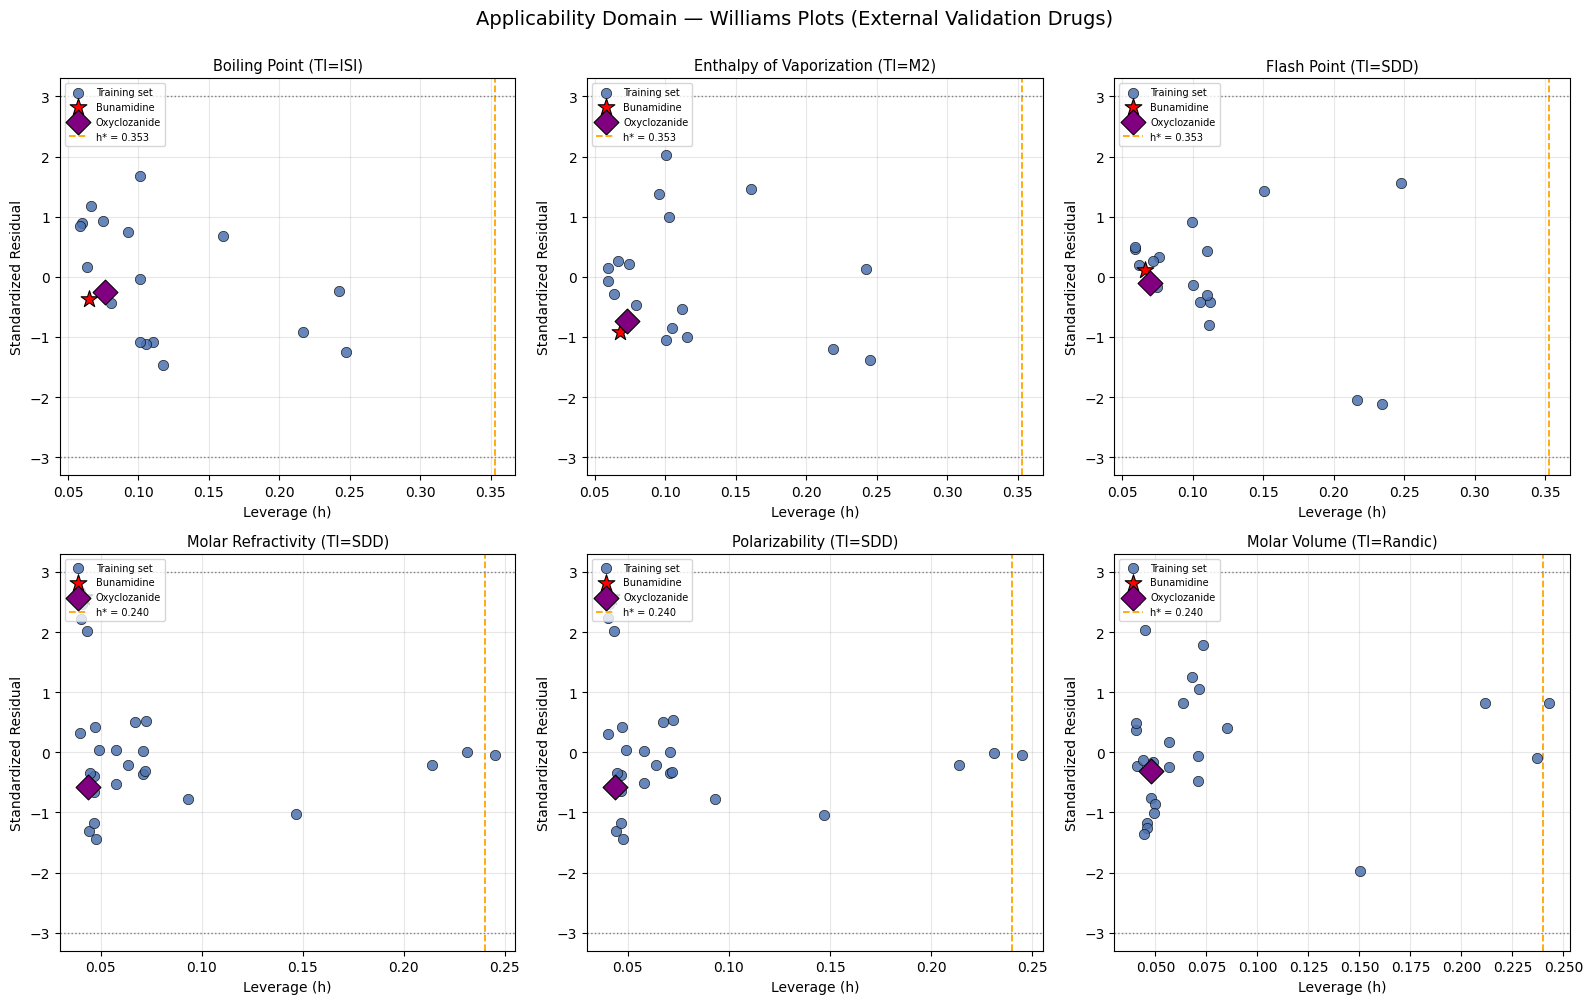

=== Applicability Domain Summary ===
        Drug               Property Predictor_TI  h_star_threshold  Leverage  Std_Residual  Within_Leverage  Within_Residual  Within_AD  Model_valid
  Bunamidine           BoilingPoint          ISI            0.3529    0.0647       -0.3648             True             True       True         True
Oxyclozanide           BoilingPoint          ISI            0.3529    0.0762       -0.2587             True             True       True         True
  Bunamidine EnthalpyOfVaporization           M2            0.3529    0.0679       -0.9258             True             True       True         True
Oxyclozanide EnthalpyOfVaporization           M2            0.3529    0.0731       -0.7403             True             True       True         True
  Bunamidine             FlashPoint          SDD            0.3529    0.0662        0.1168             True             True       True        False
Oxyclozanide             FlashPoint          SDD            0.3529   

In [12]:
# ============================================================
# CELL 10: Applicability Domain — Leverage (Williams Plot)
# SLR leverage on the selected index; residuals = LOO residuals,
# external errors standardized by the SD of the training LOO residuals
# h* = 3(k+1)/n with k = 1
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def compute_leverage(x_train, x_query):
    n = len(x_train)
    x_mean = np.mean(x_train)
    ss_x = np.sum((x_train - x_mean) ** 2)
    h_train = 1/n + (x_train - x_mean) ** 2 / ss_x
    h_query = 1/n + (x_query - x_mean) ** 2 / ss_x
    h_star = 3 * (1 + 1) / n
    return h_train, h_query, h_star

ext_colors = {'Bunamidine': 'red', 'Oxyclozanide': 'purple'}
ext_markers = {'Bunamidine': '*', 'Oxyclozanide': 'D'}

ad_rows = []
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, prop in enumerate(PROPERTY_COLS):
    ax = axes[idx]
    sub = merged_df[['Drug', prop] + TI_COLS].dropna(subset=[prop]).reset_index(drop=True)
    n = len(sub)

    ti_used = slr_summary_df.loc[slr_summary_df['Property'] == prop, 'Best_TI'].values[0]
    x_train = sub[ti_used].values

    pred_data = slr_loo_predictions[prop]
    y_true, y_pred_cv = pred_data['y_true'], pred_data['y_pred_cv']
    resid = y_true - y_pred_cv
    sd_resid = np.std(resid, ddof=1)
    resid_std = resid / sd_resid

    h_train, _, h_star = compute_leverage(x_train, x_train)
    ax.scatter(h_train, resid_std, s=55, color='#4C72B0', edgecolor='black',
               linewidth=0.5, alpha=0.85, label='Training set', zorder=3)

    for drug_name in external.keys():
        x_ext = ext_ti_cache[drug_name][ti_used]
        _, h_ext, _ = compute_leverage(x_train, x_ext)

        ext_row = validation_df[(validation_df['Drug'] == drug_name) &
                                (validation_df['Property'] == prop) &
                                (validation_df['Model'] == 'SLR')].iloc[0]
        # same sign convention as training: (actual - predicted)
        ext_resid_std = (ext_row['Reference_ACDLabs'] - ext_row['Predicted']) / sd_resid

        ax.scatter([h_ext], [ext_resid_std], s=160, color=ext_colors[drug_name],
                   marker=ext_markers[drug_name], edgecolor='black', linewidth=0.8,
                   label=drug_name, zorder=4)

        ad_rows.append({
            'Drug': drug_name, 'Property': prop, 'Predictor_TI': ti_used,
            'h_star_threshold': h_star, 'Leverage': h_ext,
            'Std_Residual': ext_resid_std,
            'Within_Leverage': h_ext <= h_star,
            'Within_Residual': abs(ext_resid_std) <= 3,
            'Within_AD': (h_ext <= h_star) and (abs(ext_resid_std) <= 3),
            'Model_valid': prop != 'FlashPoint'
        })

    ax.axvline(h_star, color='orange', linestyle='--', linewidth=1.3, label=f'h* = {h_star:.3f}')
    ax.axhline(3, color='gray', linestyle=':', linewidth=1)
    ax.axhline(-3, color='gray', linestyle=':', linewidth=1)

    ax.set_xlabel('Leverage (h)', fontsize=10)
    ax.set_ylabel('Standardized Residual', fontsize=10)
    ax.set_title(f"{PROPERTY_LABELS[prop].replace(chr(10), ' ')} (TI={ti_used})", fontsize=10.5)
    ax.legend(loc='upper left', fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle('Applicability Domain — Williams Plots (External Validation Drugs)', fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/williams_plot_external_validation.png', dpi=300, bbox_inches='tight')
plt.show()

ad_df = pd.DataFrame(ad_rows)
ad_df.to_csv(f'{PROJECT_DIR}/results/applicability_domain_external.csv', index=False)
print("=== Applicability Domain Summary ===")
print(ad_df.round(4).to_string(index=False))

for drug in external.keys():
    sub_ad = ad_df[(ad_df['Drug'] == drug) & ad_df['Model_valid']]
    print(f"\n{drug}: within AD (leverage and residual) for "
          f"{sub_ad['Within_AD'].sum()}/{len(sub_ad)} valid properties")

In [13]:
# ============================================================
# CELL 11: Consolidated Results Export (supplementary workbook + summary text)
# ============================================================
import os, sys, platform
from datetime import datetime
import numpy as np
import pandas as pd
import sklearn, scipy

RES = f'{PROJECT_DIR}/results'
output_path = f'{RES}/QSPR_Anthelmintic_Complete_Results.xlsx'

# --- SLR leave-one-out predictions in long format ---
loo_rows = []
for prop, data in slr_loo_predictions.items():
    ti_name = data.get('best_TI', data.get('predictor_TI'))
    for drug, yt, yp in zip(data['Drug'], data['y_true'], data['y_pred_cv']):
        loo_rows.append({'Property': prop, 'Drug': drug, 'Best_TI': ti_name,
                         'Actual': yt, 'LOO_CV_Predicted': yp, 'Residual': yt - yp})
loo_pred_df = pd.DataFrame(loo_rows)

# --- External validation: summary per drug and model (flash point excluded) ---
ext_valid = validation_df[validation_df['Property'] != 'FlashPoint']
ext_summary = (ext_valid.groupby(['Drug', 'Model'])['AbsPctError']
               .agg(['mean', 'max']).round(2).reset_index()
               .rename(columns={'mean': 'Mean_AbsPctError', 'max': 'Max_AbsPctError'}))

# --- Run metadata ---
metadata = pd.DataFrame([
    {'Field': 'Study', 'Value': 'Degree-based topological indices for property prediction of anthelmintic drugs'},
    {'Field': 'Training set size', 'Value': f'{merged_df.shape[0]} drugs'},
    {'Field': 'External validation drugs', 'Value': ', '.join(external.keys())},
    {'Field': 'Topological indices', 'Value': ', '.join(TI_COLS)},
    {'Field': 'Properties', 'Value': ', '.join(PROPERTY_COLS)},
    {'Field': 'Property source', 'Value': 'ACD/Labs Percepta predictions displayed on ChemSpider'},
    {'Field': 'Property retrieval date', 'Value': str(globals().get('PROPERTY_RETRIEVED', 'not set'))},
    {'Field': 'Models', 'Value': 'SLR (baseline); forward stepwise LR (alpha=0.01, max 3 predictors, VIF<=10); SVR (RBF)'},
    {'Field': 'Validation', 'Value': 'LOO-CV; criteria R2>0.85, Q2>0.80, R2-Q2<0.10'},
    {'Field': 'SVR search', 'Value': 'GridSearchCV inside each LOO fold; inner 5-fold shuffled CV (seed 42), MSE scoring; '
                                     'C {10,50,100,500}, epsilon {0.1,0.2,0.3,0.5}, gamma {scale,auto}'},
    {'Field': 'Random seed', 'Value': str(globals().get('SEED', 42))},
    {'Field': 'Python', 'Value': sys.version.split()[0]},
    {'Field': 'RDKit', 'Value': Chem.rdBase.rdkitVersion},
    {'Field': 'scikit-learn', 'Value': sklearn.__version__},
    {'Field': 'scipy / numpy / pandas', 'Value': f'{scipy.__version__} / {np.__version__} / {pd.__version__}'},
    {'Field': 'Generated on', 'Value': datetime.now().strftime('%Y-%m-%d %H:%M:%S')},
])

# --- Sheets built from objects in memory: (sheet name, DataFrame, write index?) ---
sheets = [
    ('00_Metadata', metadata, False),
    ('01_Merged_Dataset', merged_df, False),
    ('02_Descriptive_Stats', desc_df, False),
    ('03_Correlation_Matrix', corr_matrix, True),
    ('04_Correlation_Pairwise_N', n_pairs, True),
    ('05_SLR_Best_TI_Summary', slr_summary_df, False),
    ('06_SLR_All_TI_Candidates', slr_all_candidates_df, False),
    ('07_Stepwise_LR_Summary', stepwise_summary_df, False),
    ('08_SVR_Summary', svr_summary_df, False),
    ('09_Model_Comparison', comparison_df, False),
    ('10_External_Validation', validation_df, False),
    ('11_Ext_Valid_Summary', ext_summary, False),
    ('12_Applicability_Domain', ad_df, False),
    ('13_SLR_LOOCV_Predictions', loo_pred_df, False),
]

# --- Sheets read from CSVs written by earlier cells (skipped with a warning if missing) ---
csv_sheets = [
    ('14_SLR_R2_matrix', 'SLR_R2_matrix.csv'),
    ('15_SLR_Q2_matrix', 'SLR_Q2_matrix.csv'),
    ('16_Stepwise_candidates', 'stepwise_all_candidates.csv'),
    ('17_Stepwise_VIF_summary', 'stepwise_vif_summary.csv'),
    ('18_Stepwise_index_corr', 'stepwise_index_correlations.csv'),
    ('19_SVR_LOOCV_Predictions', 'SVR_loo_predictions.csv'),
    ('20_SLR_vs_SVR', 'SLR_vs_SVR_comparison.csv'),
    ('21_External_TIs', 'external_drugs_TIs.csv'),
    ('22_External_Table', 'external_validation_table9.csv'),
]

with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    for name, df, write_index in sheets:
        df.to_excel(writer, sheet_name=name, index=write_index)
    for name, fname in csv_sheets:
        path = f'{RES}/{fname}'
        if os.path.exists(path):
            tmp = pd.read_csv(path)
            if tmp.columns[0].startswith('Unnamed'):
                tmp = tmp.rename(columns={tmp.columns[0]: 'Index'})
            tmp.to_excel(writer, sheet_name=name, index=False)
        else:
            print(f'WARNING: {fname} not found -> sheet {name} not written')

print(f'Workbook saved: {output_path}')

# --- Plain-text summary, all numbers computed from the tables above ---
fp = comparison_df[comparison_df['Property'] == 'FlashPoint'].iloc[0]
ad_lines = []
for drug in external.keys():
    s = ad_df[(ad_df['Drug'] == drug) & ad_df['Model_valid']]
    ad_lines.append(f"{drug}: {int(s['Within_AD'].sum())}/{len(s)} valid properties within the applicability domain")

summary_text = f"""
QSPR ANTHELMINTIC DRUGS -- RESULTS SUMMARY
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
Training set: {merged_df.shape[0]} drugs; external: {', '.join(external.keys())}

=== SLR (baseline), best index per property ===
{slr_summary_df[['Property', 'Best_TI', 'R2', 'Q2', 'RMSE_CV', 'Meets_Criteria']].round(4).to_string(index=False)}

=== STEPWISE ===
{stepwise_summary_df[['Property', 'Selected_TIs', 'R2', 'Q2', 'Meets_Criteria']].round(4).to_string(index=False)}

=== SVR (RBF) ===
{svr_summary_df[['Property', 'Predictor_TI', 'Q2', 'RMSE_CV', 'R2', 'R2_minus_Q2', 'Meets_Criteria']].round(4).to_string(index=False)}

=== EXTERNAL VALIDATION (absolute % error, flash point excluded) ===
{ext_summary.to_string(index=False)}

=== APPLICABILITY DOMAIN ===
{chr(10).join(ad_lines)}

=== LIMITATION ===
Flash point fails the criteria for every model (SLR Q2={fp['SLR_Q2']:.3f}, stepwise Q2={fp['Stepwise_Q2']:.3f},
SVR Q2={fp['SVR_Q2']:.3f}); flash point is not interpreted or used for external prediction.
"""
with open(f'{RES}/key_findings_summary.txt', 'w') as f:
    f.write(summary_text)
print(summary_text)

Workbook saved: /content/drive/MyDrive/QSPR_Anthelmintic_repo/results/QSPR_Anthelmintic_Complete_Results.xlsx

QSPR ANTHELMINTIC DRUGS -- RESULTS SUMMARY
Generated: 2026-10-26 04:16:26
Training set: 25 drugs; external: Bunamidine, Oxyclozanide

=== SLR (baseline), best index per property ===
              Property Best_TI     R2     Q2  RMSE_CV  Meets_Criteria
          BoilingPoint     ISI 0.9781 0.9720  39.8186            True
EnthalpyOfVaporization      M2 0.9918 0.9891   4.0646            True
            FlashPoint     SDD 0.5907 0.3696  95.1329           False
     MolarRefractivity     SDD 0.9843 0.9826   7.7111            True
        Polarizability     SDD 0.9843 0.9826   3.0543            True
           MolarVolume  Randic 0.9805 0.9770  27.7439            True

=== STEPWISE ===
              Property Selected_TIs     R2     Q2  Meets_Criteria
          BoilingPoint          ISI 0.9781 0.9720            True
EnthalpyOfVaporization           M2 0.9918 0.9891            True
 

In [14]:
   !ls -R /content/drive/MyDrive/QSPR_Anthelmintic_repo | head -80

/content/drive/MyDrive/QSPR_Anthelmintic_repo:
data
figures
results

/content/drive/MyDrive/QSPR_Anthelmintic_repo/data:
anthelmintic_properties_chemspider.xlsx
external validation drugs.xlsx
merged_TI_properties_25drugs.csv
topological_indices_25drugs.csv

/content/drive/MyDrive/QSPR_Anthelmintic_repo/figures:
pearson_correlation_heatmap.png
Q2_comparison_barchart.png
RMSE_comparison_barchart.png
SVR_actual_vs_predicted_scatter.png
williams_plot_external_validation.png

/content/drive/MyDrive/QSPR_Anthelmintic_repo/results:
applicability_domain_external.csv
correlation_pairwise_n.csv
descriptive_statistics.csv
environment.txt
external_drugs_TIs.csv
external_validation.csv
external_validation_table9.csv
key_findings_summary.txt
model_comparison_summary.csv
pearson_correlation_matrix.csv
QSPR_Anthelmintic_Complete_Results.xlsx
SLR_all_candidates.csv
SLR_best_TI_summary.csv
SLR_index_ranking.csv
SLR_Q2_matrix.csv
SLR_R2_matrix.csv
SLR_vs_SVR_comparison.csv
stepwise_all_candidates.csv
ste